In [2]:
#PART A OF ASSIGNMENT
import os
print("Current folder:", os.getcwd())
print("Available files:", os.listdir())
print("CSV exists:", os.path.exists("sales_raw.csv"))

Current folder: C:\Users\Hafeez Ahmed\Desktop\Bootcamp Practices\Boootcamp Assignments\Sunday Project
Available files: ['.idea', '.venv', 'notebook1.ipynb', 'PyCharmMiscProject.iml', 'sales_raw.csv', 'Sunday_Project.ipynb']
CSV exists: True


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
#Loading CSV File
sales = pd.read_csv("sales_raw.csv")

# Displaying first five rows
sales.head()

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


Dataset Shape: (21, 6)

Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data Types:
transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object

Missing Values:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate Rows:
1
Rows Before Cleaning: 21
Rows After Cleaning: 14
Rows Removed: 7


,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,2026-10-01,North,Food,2.0,120.0,240.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0
2,1003,2026-10-02,North,Food,3.0,110.0,330.0
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0
4,1005,2026-10-03,South,Books,2.0,250.0,500.0


Revenue by Region:
region
East       740.0
North    11470.0
South     1035.0
West       530.0
Name: revenue, dtype: float64

Revenue by Category:
category
Books          1370.0
Food           1945.0
Stationery    10460.0
Name: revenue, dtype: float64


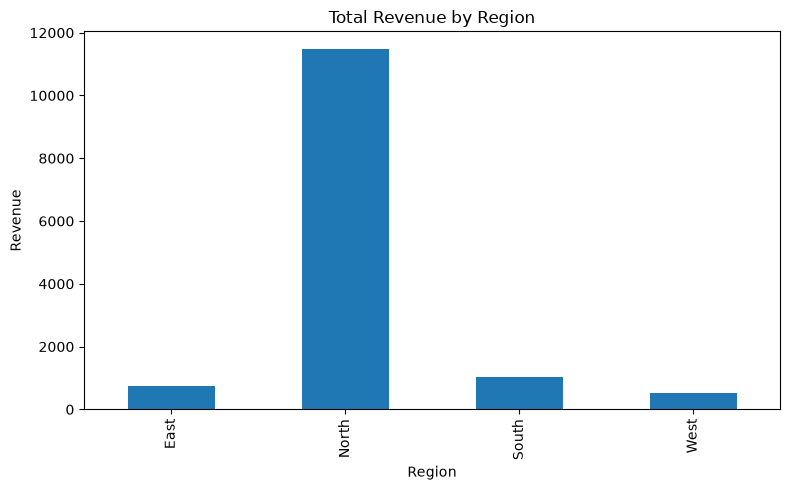

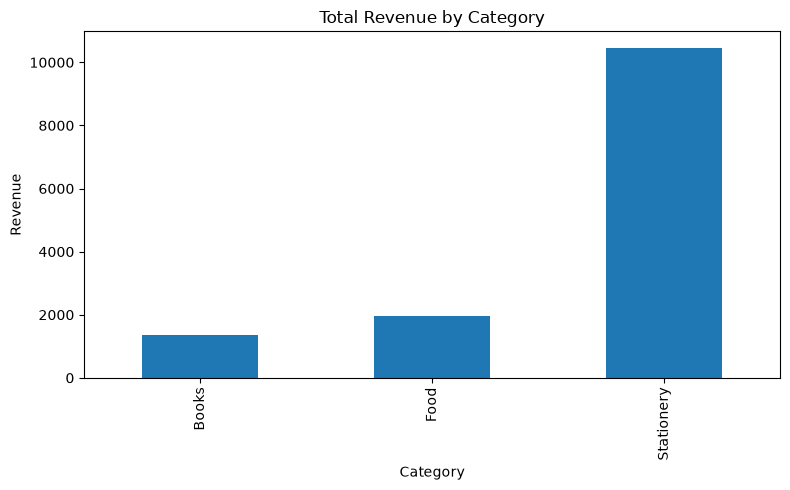

cleaned_sales.csv saved successfully!


In [4]:
# Displaying dataset shape
print("Dataset Shape:", sales.shape)

# Displaying column names
print("\nColumn Names:")
print(sales.columns.tolist())

# Displaying data types
print("\nData Types:")
print(sales.dtypes)

# Check missing values
print("\nMissing Values:")
print(sales.isna().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(sales.duplicated().sum())
# Create a copy of the original dataset
cleaned = sales.copy()

# Count rows before cleaning
rows_before = len(cleaned)

# Removing extra spaces and standardize text
cleaned["region"] = (
    cleaned["region"].astype("string").str.strip().str.title()
)

cleaned["category"] = (
    cleaned["category"].astype("string").str.strip().str.title()
)

# Converting date and numeric columns
cleaned["sale_date"] = pd.to_datetime(
    cleaned["sale_date"], errors="coerce"
)

cleaned["quantity"] = pd.to_numeric(
    cleaned["quantity"], errors="coerce"
)

cleaned["unit_price"] = pd.to_numeric(
    cleaned["unit_price"], errors="coerce"
)

# Removing duplicate records
cleaned = cleaned.drop_duplicates()

# Removing records with missing essential values
cleaned = cleaned.dropna(
    subset=[
        "transaction_id",
        "sale_date",
        "region",
        "category",
        "quantity",
        "unit_price"
    ]
)

# Removing invalid prices and quantities
cleaned = cleaned[
    (cleaned["unit_price"] > 0) &
    (cleaned["quantity"] > 0)
]

# Counting rows after cleaning
rows_after = len(cleaned)

print("Rows Before Cleaning:", rows_before)
print("Rows After Cleaning:", rows_after)
print("Rows Removed:", rows_before - rows_after)

# Calculate revenue
cleaned["revenue"] = (
    cleaned["quantity"] * cleaned["unit_price"]
)

# Display first five rows
display(cleaned.head())

# Revenue by region
revenue_by_region = (
    cleaned.groupby("region")["revenue"].sum()
)

print("Revenue by Region:")
print(revenue_by_region)

# Revenue by category
revenue_by_category = (
    cleaned.groupby("category")["revenue"].sum()
)

print("\nRevenue by Category:")
print(revenue_by_category)

# Creating revenue chart by region
plt.figure(figsize=(8, 5))

revenue_by_region.plot(kind="bar")

plt.title("Total Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")

plt.tight_layout()

# Save chart
plt.savefig("revenue_by_region.png")

plt.show()

# Creating revenue chart by category
plt.figure(figsize=(8, 5))

revenue_by_category.plot(kind="bar")

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.tight_layout()

# Saving chart
plt.savefig("revenue_by_category.png")

plt.show()

# Converting date into a standard format
cleaned["sale_date"] = cleaned["sale_date"].dt.strftime("%Y-%m-%d")

# Exporting cleaned dataset
cleaned.to_csv("cleaned_sales.csv", index=False)

print("cleaned_sales.csv saved successfully!")

In [5]:
#PART B OF ASSIGNMENT

# Loading cleaned dataset
updated_sales = pd.read_csv("cleaned_sales.csv")

# Calculating 5% tax
updated_sales["tax_amount"] = updated_sales["revenue"] * 0.05

# Display first five rows
display(updated_sales.head())

# Increase Books unit price by 10%
updated_sales.loc[
    updated_sales["category"] == "Books",
    "unit_price"
] *= 1.10

# Recalculate revenue
updated_sales["revenue"] = (
    updated_sales["quantity"] * updated_sales["unit_price"]
)

# Recalculate tax
updated_sales["tax_amount"] = (
    updated_sales["revenue"] * 0.05
)

# Displaying updated records
display(updated_sales.head())

print(updated_sales["transaction_id"].tolist())

# Select an existing transaction ID
selected_transaction_id = 1001

# Remove the selected transaction
updated_sales = updated_sales.loc[
    updated_sales["transaction_id"] != selected_transaction_id
].copy()

print("Selected transaction removed:", selected_transaction_id)

# Creating temporary review status column
updated_sales["review_status"] = "Pending"

# Removing temporary column
updated_sales = updated_sales.drop(
    columns=["review_status"]
)

display(updated_sales.head())

# Save updated CSV
updated_sales.to_csv("sales_updated.csv", index=False)

# Read the saved file again
verified_sales = pd.read_csv("sales_updated.csv")

# Display first five rows
display(verified_sales.head())

# Display final column names
print("Final Column Names:")
print(verified_sales.columns.tolist())



,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1.0,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2.0,250.0,500.0,25.0


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2.0,120.0,240.0,12.00
1,1002,2026-10-01,South,Books,1.0,275.0,275.0,13.75
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.50
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.00
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.50


[1001, 1002, 1003, 1004, 1005, 1007, 1008, 1009, 1012, 1015, 1016, 1017, 1019, 1020]
Selected transaction removed: 1001


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
1,1002,2026-10-01,South,Books,1.0,275.0,275.0,13.75
2,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.50
3,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.00
4,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.50
5,1007,2026-10-04,North,Stationery,3.0,60.0,180.0,9.00


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1002,2026-10-01,South,Books,1.0,275.0,275.0,13.75
1,1003,2026-10-02,North,Food,3.0,110.0,330.0,16.50
2,1004,2026-10-02,East,Stationery,4.0,50.0,200.0,10.00
3,1005,2026-10-03,South,Books,2.0,275.0,550.0,27.50
4,1007,2026-10-04,North,Stationery,3.0,60.0,180.0,9.00


Final Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
